# Tugas 05 — Transfer Learning
Google Colab: pilih **Runtime → Change runtime type → T4 GPU**, kemudian Run all.
Andrew Wijaya | NIM 2802508363. Notebook ini menyimpan output eksperimen aktual; metrik cocok dengan raw_logs/.
B1/B2/B3 menggunakan augmentasi. B4 membandingkan B3 dengan dan tanpa augmentasi.
B3 mengikuti ketentuan eksplisit PDF: layer4 dan fc dibuka sejak awal, tanpa tahap warmup tambahan.
B5 opsional mengikuti strategi/augmentasi ResNet terbaik berdasarkan validation loss.
Analisis Bagian A (100–150 kata per nomor), laporan 3–5 halaman, hipotesis misklasifikasi,
dan kesimpulan perlu ditulis mandiri. Sertakan disclosure bantuan Codex untuk penyusunan kode,
serta cara Anda memverifikasinya. Slide asli belum diberikan; nomor slide berasal dari PDF tugas.

In [ ]:
import importlib.util
import subprocess
import sys

missing = [package for package,
    module in [("scikit-learn", "sklearn"), ("pandas", "pandas"), ("matplotlib", "matplotlib"), ("tqdm", "tqdm")] if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])


In [ ]:
import gc
import json
import os
import platform
import random
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from PIL import Image
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, models, transforms
from tqdm.auto import tqdm

SEED = 42
BATCH_SIZE = 32
MAX_EPOCHS = 30
PATIENCE = 5
NUM_WORKERS = 2
RUN_BONUS = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT = Path("/content/tugas05_outputs")
OUTPUT.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path("/content/pet_data")

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)

def seed_worker(worker_id):
    seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(seed)
    random.seed(seed)

seed_everything()
environment = {"python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name() if DEVICE.type == "cuda" else None}
(OUTPUT / "environment.json").write_text(json.dumps(environment, indent=2))
print(environment)
if DEVICE.type != "cuda":
    print("Aktifkan T4 GPU di Colab agar eksperimen lebih cepat.")


{'python': '3.13.16', 'torch': '2.11.0+cpu', 'torchvision': '0.26.0+cpu', 'device': 'cpu', 'gpu': None}
Aktifkan T4 GPU di Colab agar eksperimen lebih cepat.


## Dataset dan split
Gabungkan pool resmi trainval/test, lalu buat split internal sesuai tugas.
Metadata dibaca dari annotations resmi agar tidak bergantung pada atribut privat torchvision.
Lima ras kucing dan lima ras anjing ditentukan sebelum eksperimen. Label dipetakan ke 0–9.

In [ ]:
datasets.OxfordIIITPet(DATA_ROOT, split="trainval", target_types="category", download=True)
datasets.OxfordIIITPet(DATA_ROOT, split="test", target_types="category", download=True)
CLASS_NAMES = ["Abyssinian",
    "Bengal",
    "Birman",
    "Bombay",
    "British_Shorthair",
    "american_bulldog",
    "american_pit_bull_terrier",
    "basset_hound",
    "beagle",
    "boxer"]
class_to_index = {name: index for index, name in enumerate(CLASS_NAMES)}
pet_root = DATA_ROOT / "oxford-iiit-pet"
records = []
for official_split in ["trainval", "test"]:
    for line in (pet_root / "annotations" / f"{official_split}.txt").read_text().splitlines():
        if not line.strip() or line.startswith("#"):
            continue
        image_id, _, species, _ = line.split()
        breed = image_id.rsplit("_", 1)[0]
        if breed in class_to_index:
            records.append({"path": str(pet_root / "images" / f"{image_id}.jpg"),
                "label": class_to_index[breed],
                "breed": breed,
                "species": int(species)})
frame = pd.DataFrame(records)
assert frame.path.is_unique
assert frame.breed.nunique() == 10
assert frame.groupby("species").breed.nunique().to_dict() == {1: 5, 2: 5}
indices = np.arange(len(frame))
train_indices, remaining = train_test_split(indices,
    test_size=0.30,
    stratify=frame.label,
    random_state=SEED)
val_indices, test_indices = train_test_split(remaining,
    test_size=0.50,
    stratify=frame.iloc[remaining].label,
    random_state=SEED)
SPLITS = {"train": train_indices, "validation": val_indices, "test": test_indices}
assert not (set(train_indices) & set(val_indices) or set(train_indices) & set(test_indices) or set(val_indices) & set(test_indices))
assert sum(map(len, SPLITS.values())) == len(frame)
for split, selected in SPLITS.items():
    assert set(frame.iloc[selected].label) == set(range(10))
    frame.loc[selected, "split"] = split
frame.to_csv(OUTPUT / "split_manifest.csv", index=False)
display(pd.crosstab(frame.breed, frame.split))
print({name: {"count": len(ids), "fraction": len(ids) / len(frame)} for name,
    ids in SPLITS.items()})


100%|██████████| 792M/792M [00:27<00:00, 29.1MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.9MB/s]


split,test,train,validation
breed,,,
Abyssinian,30,138,30
Bengal,30,140,30
Birman,30,140,30
Bombay,28,129,27
British_Shorthair,30,140,30
american_bulldog,30,140,30
american_pit_bull_terrier,30,140,30
basset_hound,30,140,30
beagle,30,140,30


{'train': {'count': 1386, 'fraction': 0.6996466431095406}, 'validation': {'count': 297, 'fraction': 0.14992428066633012}, 'test': {'count': 298, 'fraction': 0.15042907622412924}}


In [ ]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
eval_transform = transforms.Compose([transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
aug_transform = transforms.Compose([transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

class PetSubset(Dataset):
    def __init__(self, records, transform):
        self.records = records.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        row = self.records.iloc[index]
        with Image.open(row.path) as image:
            tensor = self.transform(image.convert("RGB"))
        return tensor, int(row.label)

def make_loader(indices, transform, shuffle=False):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(PetSubset(frame.iloc[indices], transform),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=DEVICE.type == "cuda",
        worker_init_fn=seed_worker,
        generator=generator)

def make_loaders(augmentation):
    return {"train": make_loader(train_indices, aug_transform if augmentation else eval_transform, True),
        "train_eval": make_loader(train_indices, eval_transform),
        "validation": make_loader(val_indices, eval_transform),
        "test": make_loader(test_indices, eval_transform)}

images, labels = next(iter(make_loader(val_indices, eval_transform)))
assert images.shape[1:] == (3, 224, 224)
assert 0 <= labels.min() <= labels.max() < 10
print("Batch:", images.shape, labels.shape)


Batch: torch.Size([32, 3, 224, 224]) torch.Size([32])


In [ ]:
@dataclass(frozen=True)
class Experiment:
    name: str
    strategy: str
    augmentation: bool = True
    architecture: str = "resnet18"

    def __post_init__(self):
        if self.strategy not in {"scratch", "feature", "finetune"}:
            raise ValueError(f"Unsupported strategy: {self.strategy}")
        if self.architecture not in {"resnet18", "mobilenet_v3_small"}:
            raise ValueError(f"Unsupported architecture: {self.architecture}")
        if (
            not self.name
            or self.name in {".", ".."}
            or "/" in self.name
            or "\\" in self.name
        ):
            raise ValueError("Experiment name must be a directory name")

def build_model(config, pretrained=True):
    use_weights = pretrained and config.strategy != "scratch"
    if config.architecture == "resnet18":
        weights = models.ResNet18_Weights.IMAGENET1K_V1 if use_weights else None
        model = models.resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, len(CLASS_NAMES))
        head, block = model.fc, model.layer4
    else:
        weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1 if use_weights else None
        model = models.mobilenet_v3_small(weights=weights)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(CLASS_NAMES))
        head, block = model.classifier, model.features[-4:]
    for parameter in model.parameters():
        parameter.requires_grad = config.strategy == "scratch"
    if config.strategy != "scratch":
        for parameter in head.parameters():
            parameter.requires_grad = True
        if config.strategy == "finetune":
            for parameter in block.parameters():
                parameter.requires_grad = True
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    if config.architecture == "resnet18" and config.strategy == "feature":
        assert trainable == 5130
    if config.strategy == "scratch":
        groups = [{"params": model.parameters(), "lr": 1e-3, "name": "all"}]
    else:
        groups = [{"params": head.parameters(), "lr": 1e-3, "name": "head"}]
        if config.strategy == "finetune":
            groups.insert(0, {"params": block.parameters(), "lr": 1e-4, "name": "last_block"})
    print(config.name, "trainable parameters:", f"{trainable:,}")
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(groups, weight_decay=1e-2)
    return model, optimizer

def set_training_mode(model, config):
    if config.strategy == "scratch":
        model.train()
    else:
        model.eval()
        if config.architecture == "resnet18":
            model.fc.train()
            if config.strategy == "finetune":
                model.layer4.train()
        else:
            model.classifier.train()
            if config.strategy == "finetune":
                model.features[-4:].train()

def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, config, optimizer=None):
    training = optimizer is not None
    if training:
        set_training_mode(model, config)
    else:
        model.eval()
    total_loss, correct, count = 0.0, 0, 0
    targets, predictions, confidences = [], [], []
    with torch.set_grad_enabled(training):
        for inputs, labels in loader:
            inputs = inputs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(inputs)
            loss = criterion(logits, labels)
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss")
            if training:
                loss.backward()
                optimizer.step()
            confidence, predicted = logits.detach().softmax(1).max(1)
            total_loss += loss.item() * len(labels)
            correct += (predicted == labels).sum().item()
            count += len(labels)
            targets.extend(labels.cpu().tolist())
            predictions.extend(predicted.cpu().tolist())
            confidences.extend(confidence.cpu().tolist())
    if count == 0:
        raise ValueError("Cannot evaluate an empty loader")
    return {"loss": total_loss / count,
        "accuracy": correct / count,
        "targets": targets,
        "predictions": predictions,
        "confidences": confidences}


## Eksperimen
Early stopping memakai validation loss, patience 5, dan maksimum 30 epoch sebagai batas komputasi.
Best epoch dan jumlah epoch yang dijalankan dicatat terpisah; mencapai batas epoch bukan bukti konvergensi.
BatchNorm pada backbone beku tetap eval agar running statistics tidak berubah.
Generalization gap memakai train set deterministik dalam eval mode agar sebanding dengan validation.
Kontrol B4 membandingkan paket augmentasi lengkap, termasuk RandomResizedCrop,
dengan Resize + CenterCrop. Efek masing-masing transformasi tidak dipisahkan.
Hipotesis awal (belum merupakan hasil):
- H1: B2/B3 memberi Macro F1 lebih tinggi daripada B1 pada data terbatas.
- H2: B3 dapat meningkatkan F1 dibanding B2, dengan biaya training lebih besar.
- H3: Augmentasi dapat mengurangi gap train-validation; dampaknya harus diuji.
Single seed tidak cukup untuk menyatakan perbedaan kecil signifikan.
Waktu pelatihan mencakup training, validation, dan penyimpanan checkpoint, tidak mencakup download/model initialization.

In [ ]:
def train_experiment(config):
    seed_everything()
    loaders = make_loaders(config.augmentation)
    model, optimizer = build_model(config)
    folder = OUTPUT / config.name
    folder.mkdir(exist_ok=True)
    history = []
    best_loss, best_epoch, stale = float("inf"), 0, 0
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    synchronize()
    start = time.perf_counter()
    for epoch in tqdm(range(1, MAX_EPOCHS + 1), desc=config.name):
        synchronize()
        epoch_start = time.perf_counter()
        train = run_epoch(model, loaders["train"], config, optimizer)
        validation = run_epoch(model, loaders["validation"], config)
        synchronize()
        row = {"epoch": epoch,
            "train_loss": train["loss"],
            "train_accuracy": train["accuracy"],
            "val_loss": validation["loss"],
            "val_accuracy": validation["accuracy"],
            "seconds": time.perf_counter() - epoch_start}
        row.update({f"lr_{group['name']}": group["lr"] for group in optimizer.param_groups})
        history.append(row)
        pd.DataFrame(history).to_csv(folder / "history.csv", index=False)
        if validation["loss"] < best_loss:
            best_loss, best_epoch, stale = validation["loss"], epoch, 0
            torch.save(model.state_dict(), folder / "best.pt")
        else:
            stale += 1
        if stale >= PATIENCE:
            break
    synchronize()
    training_seconds = time.perf_counter() - start
    model.load_state_dict(torch.load(folder / "best.pt", map_location=DEVICE, weights_only=True))
    train_eval = run_epoch(model, loaders["train_eval"], config)
    validation = run_epoch(model, loaders["validation"], config)
    result = {**asdict(config),
        "seed": SEED,
        "trainable_parameters": trainable,
        "total_parameters": total,
        "learning_rates": {g["name"]: g["lr"] for g in optimizer.param_groups},
        "best_epoch": best_epoch,
        "epochs_run": len(history),
        "stop_reason": "early_stopping" if stale >= PATIENCE else "max_epochs",
        "training_seconds": training_seconds,
        "validation_loss": validation["loss"],
        "validation_accuracy": validation["accuracy"],
        "train_eval_accuracy": train_eval["accuracy"],
        "generalization_gap": train_eval["accuracy"] - validation["accuracy"]}
    (folder / "metrics.json").write_text(json.dumps(result, indent=2))
    del model, optimizer, loaders
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return result

experiments = [Experiment("B1", "scratch"),
    Experiment("B2", "feature"),
    Experiment("B3", "finetune"),
    Experiment("B4_no_aug", "finetune", False)]
protocol = {"seed": SEED,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "image_size": 224,
    "mean": MEAN,
    "std": STD,
    "classes": CLASS_NAMES,
    "experiments": [asdict(c) for c in experiments]}
(OUTPUT / "protocol.json").write_text(json.dumps(protocol, indent=2))
results = [train_experiment(config) for config in experiments]
best_resnet = min(results, key=lambda result: result["validation_loss"])
if RUN_BONUS:
    bonus = Experiment("B5",
        best_resnet["strategy"],
        best_resnet["augmentation"],
        "mobilenet_v3_small")
    experiments.append(bonus)
    results.append(train_experiment(bonus))
    protocol["experiments"] = [asdict(c) for c in experiments]
    (OUTPUT / "protocol.json").write_text(json.dumps(protocol, indent=2))
best_name = min(results, key=lambda result: result["validation_loss"])["name"]
print("Model terpilih berdasarkan validation loss:", best_name)


B1 trainable parameters: 11,181,642


B1:   0%|          | 0/30 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 139MB/s]


B2 trainable parameters: 5,130


...

B3 trainable parameters: 8,398,858


B3:   0%|          | 0/30 [00:00<?, ?it/s]

B4_no_aug trainable parameters: 8,398,858


B4_no_aug:   0%|          | 0/30 [00:00<?, ?it/s]

Model terpilih berdasarkan validation loss: B4_no_aug


In [ ]:
for config, result in zip(experiments, results):
    model, optimizer = build_model(config, pretrained=False)
    del optimizer
    model.load_state_dict(torch.load(OUTPUT / config.name / "best.pt",
        map_location=DEVICE,
        weights_only=True))
    test = run_epoch(model, make_loader(test_indices, eval_transform), config)
    result["test_accuracy"] = test["accuracy"]
    result["test_macro_f1"] = f1_score(test["targets"],
        test["predictions"],
        labels=list(range(10)),
        average="macro",
        zero_division=0)
    predictions = frame.iloc[test_indices][["path", "label", "breed"]].reset_index(drop=True)
    predictions["predicted_label"] = test["predictions"]
    predictions["confidence"] = test["confidences"]
    predictions["predicted_breed"] = predictions.predicted_label.map(dict(enumerate(CLASS_NAMES)))
    predictions.to_csv(OUTPUT / config.name / "test_predictions.csv", index=False)
    report = classification_report(test["targets"],
        test["predictions"],
        labels=list(range(10)),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0)
    (OUTPUT / config.name / "classification_report.json").write_text(json.dumps(report, indent=2))
    (OUTPUT / config.name / "metrics.json").write_text(json.dumps(result, indent=2))
    del model
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

summary = pd.DataFrame(results)
summary.to_csv(OUTPUT / "experiment_summary.csv", index=False)
(OUTPUT / "experiment_summary.json").write_text(json.dumps(results, indent=2))
display(summary)


B1 trainable parameters: 11,181,642
B2 trainable parameters: 5,130
B3 trainable parameters: 8,398,858
B4_no_aug trainable parameters: 8,398,858


,name,strategy,augmentation,architecture,seed,trainable_parameters,total_parameters,learning_rates,best_epoch,epochs_run,stop_reason,training_seconds,validation_loss,validation_accuracy,train_eval_accuracy,generalization_gap,test_accuracy,test_macro_f1
0,B1,scratch,True,resnet18,42,11181642,11181642,{'all': 0.001},4,9,early_stopping,3794.933527,1.699854,0.404040,0.448052,0.044012,0.382550,0.354973
1,B2,feature,True,resnet18,42,5130,11181642,{'head': 0.001},13,18,early_stopping,3003.078963,0.223466,0.929293,0.958874,0.029582,0.912752,0.913205
2,B3,finetune,True,resnet18,42,8398858,11181642,"{'last_block': 0.0001, 'head': 0.001}",7,12,early_stopping,2659.513075,0.186832,0.962963,0.993506,0.030544,0.936242,0.936307
3,B4_no_aug,finetune,False,resnet18,42,8398858,11181642,"{'last_block': 0.0001, 'head': 0.001}",4,9,early_stopping,1965.727282,0.184115,0.949495,1.000000,0.050505,0.932886,0.933086


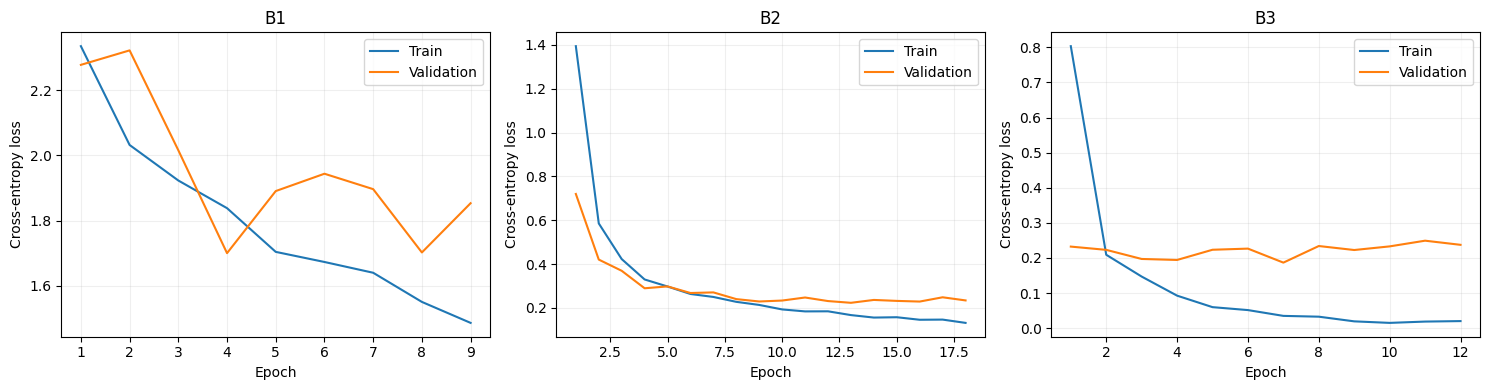

,validation_accuracy,train_eval_accuracy,generalization_gap,test_macro_f1
name,,,,
B3,0.962963,0.993506,0.030544,0.936307
B4_no_aug,0.949495,1.000000,0.050505,0.933086


,0
validation_accuracy,0.013468
train_eval_accuracy,-0.006494
generalization_gap,-0.019962
test_macro_f1,0.003221


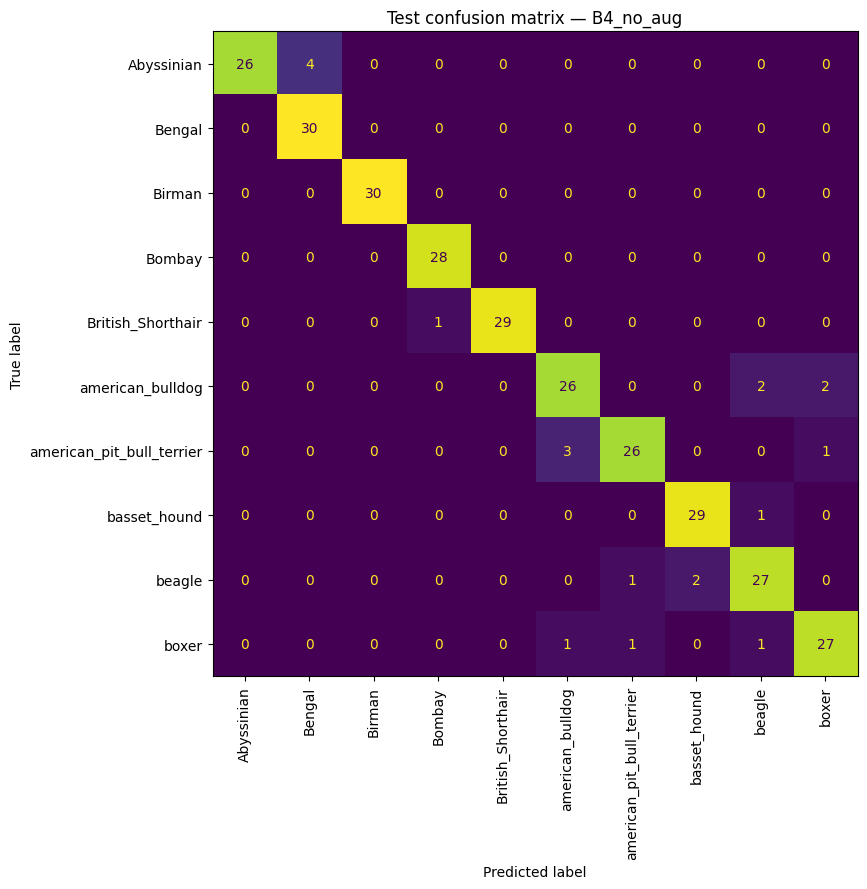

Isi failure_analysis.csv setelah memeriksa gambar:
Bukti visual: bagian tubuh/ciri yang terlihat atau tertutup.
Hipotesis: satu dugaan penyebab, maksimal 30 kata; bukan klaim pasti.


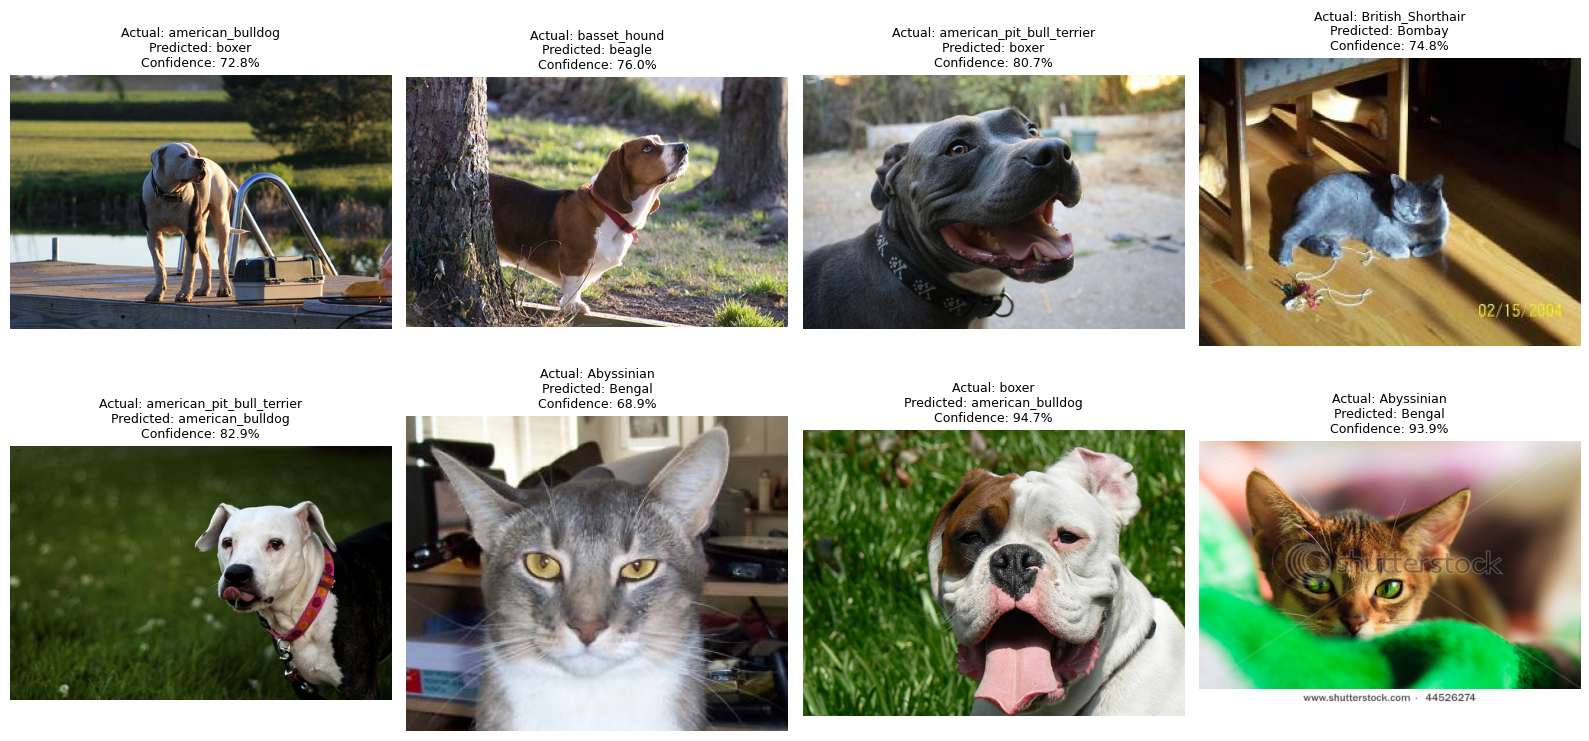

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, name in zip(axes, ["B1", "B2", "B3"]):
    history = pd.read_csv(OUTPUT / name / "history.csv")
    axis.plot(history.epoch, history.train_loss, label="Train")
    axis.plot(history.epoch, history.val_loss, label="Validation")
    axis.set(title=name, xlabel="Epoch", ylabel="Cross-entropy loss")
    axis.legend()
    axis.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT / "learning_curves.png", dpi=180)
plt.show()

control = summary.set_index("name").loc[["B3", "B4_no_aug"],
    ["validation_accuracy", "train_eval_accuracy", "generalization_gap", "test_macro_f1"]]
display(control)
delta = control.loc["B3"] - control.loc["B4_no_aug"]
delta.rename("aug_minus_no_aug").to_csv(OUTPUT / "augmentation_delta.csv")
display(delta.to_frame())

best_predictions = pd.read_csv(OUTPUT / best_name / "test_predictions.csv")
fig, axis = plt.subplots(figsize=(10, 9))
matrix = confusion_matrix(best_predictions.label,
    best_predictions.predicted_label,
    labels=list(range(10)))
ConfusionMatrixDisplay(matrix,
    display_labels=CLASS_NAMES).plot(ax=axis,
    xticks_rotation=90,
    colorbar=False)
axis.set_title(f"Test confusion matrix — {best_name}")
fig.tight_layout()
fig.savefig(OUTPUT / "confusion_matrix.png", dpi=180)
plt.show()

errors = best_predictions[best_predictions.label != best_predictions.predicted_label].head(8).copy()
# Inspect each image before choosing one evidence-backed hypothesis.
errors["visual_evidence_manual"] = ""
errors["hypothesis_manual"] = ""
errors.to_csv(OUTPUT / "failure_analysis.csv", index=False)
print("Isi failure_analysis.csv setelah memeriksa gambar:")
print("Bukti visual: bagian tubuh/ciri yang terlihat atau tertutup.")
print("Hipotesis: satu dugaan penyebab, maksimal 30 kata; bukan klaim pasti.")
if len(errors):
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    for axis in axes.flat:
        axis.axis("off")
    for axis, row in zip(axes.flat, errors.itertuples()):
        with Image.open(row.path) as image:
            axis.imshow(image.convert("RGB"))
        axis.set_title(f"Actual: {row.breed}\nPredicted: {row.predicted_breed}\nConfidence: {row.confidence:.1%}",
            fontsize=9)
    fig.tight_layout()
    fig.savefig(OUTPUT / "failure_samples.png", dpi=180)
    plt.show()
else:
    print("Tidak ada misklasifikasi pada test set; tidak ada sampel kesalahan untuk ditampilkan.")
if len(errors) < 5:
    print(f"Hanya {len(errors)} kesalahan ditemukan. Laporkan jumlah aktual tanpa membuat contoh palsu.")


## Simpan hasil
Unduh arsip hasil, lalu **File → Download → Download .ipynb** untuk menyimpan notebook dengan output sel.
Arsip otomatis hanya berisi hasil eksperimen; tambahkan notebook yang telah dieksekusi dan laporan mandiri sebelum pengumpulan.
Isi NIM/nama saat mengemas submission: `Tugas05_<NIM>_<NamaMahasiswa>.zip`.
Repositori GitHub harus memuat README dan requirements; publikasi dilakukan sendiri setelah peninjauan.

Dokumen pendamping lokal:
- `Panduan_Bagian_A.md`: kerangka pemahaman untuk ditulis ulang secara mandiri.
- `Laporan_Analisis.md`: template 3–5 halaman, isi berdasarkan log aktual.
- `README.md`: langkah eksekusi dan checklist submission.
Sel terakhir membuat draf ringkasan dari metrik aktual, bukan kesimpulan otomatis.

Referensi implementasi:
- https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.OxfordIIITPet.html
- https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html
- https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html
- https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

In [ ]:
# Generate a factual summary only after all experiments have completed.
columns = ["name", "strategy", "trainable_parameters", "learning_rates", "best_epoch",
           "epochs_run", "stop_reason", "training_seconds", "validation_accuracy",
           "test_macro_f1", "generalization_gap"]
table = summary[columns].copy()
header = " | ".join(columns)
rows = [" | ".join(str(value) for value in row) for row in table.itertuples(index=False, name=None)]
report = "\n".join([
    "# Ringkasan faktual eksperimen", "", "| " + header + " |",
    "| " + " | ".join(["---"] * len(columns)) + " |",
    *["| " + row + " |" for row in rows], "",
    f"Model terpilih berdasarkan validation loss: {best_name}.",
    "best_epoch adalah epoch checkpoint terbaik, bukan bukti konvergensi.",
    "", "## Analisis mandiri yang masih harus dilengkapi",
    "Bandingkan B1/B2/B3, jelaskan delta B4, dan kaitkan dengan slide tugas.",
    "Isi bukti visual dan hipotesis per gambar pada failure_analysis.csv.",
    "Tulis rekomendasi, batasan, dan AI disclosure setelah verifikasi mandiri.",
])
(OUTPUT / "ringkasan_faktual.md").write_text(report, encoding="utf-8")

import shutil
from importlib.metadata import version

packages = ["torch",
    "torchvision",
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "Pillow",
    "tqdm"]
(OUTPUT / "requirements.txt").write_text(
    "\n".join(f"{package}=={version(package)}" for package in packages) + "\n",
    encoding="utf-8",
)
archive = shutil.make_archive("/content/tugas05_experiment_outputs", "zip", OUTPUT)
print("Arsip hasil:", archive)
print("Tambahkan notebook beroutput dan laporan final ke ZIP submission.")
from google.colab import files
files.download(archive)


Arsip hasil: /content/tugas05_experiment_outputs.zip
Tambahkan notebook beroutput dan laporan final ke ZIP submission.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>